# Домашняя работа №3. Предсказание страховых случаев

**Студент:** Харузин Михаил Сергеевич, группа 3823Б1ПМоп2

## 0. Описание задачи

Заказчик — компания автострахования. Она хочет назначать конкурентоспособную цену на страховку, и для этого ей нужна модель, которая по данным о клиенте оценивает, насколько велик риск, что он подаст страховое требование.

Каждая строка таблицы — один клиент: номер клиента `id`, 17 признаков (возрастная группа, пол, стаж, доход, кредитный рейтинг, число нарушений и т.д.) и целевой признак `outcome` — подавал ли клиент страховое требование за прошлый год (`True` — подавал, `False` — нет).

Требуется по признакам клиента предсказать `outcome`. Это *задача бинарной классификации* (классов два). Кроме того, заказчику важно понимать, какие признаки сильнее всего влияют на риск.

Данные содержат 10 000 клиентов.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Чтение данных

In [2]:
data_raw = pd.read_csv('/kaggle/input/datasets/racholsan/customer-data/customer-data.csv')
data_raw.shape

(10000, 19)

Таблица содержит 10 000 строк (по одной на клиента) и 19 столбцов. Посмотрим на неё:

In [3]:
data_raw

,id,age,gender,race,driving_experience,education,income,credit_score,vehicle_ownership,vehicle_year,married,children,postal_code,annual_mileage,vehicle_type,speeding_violations,DUIs,past_accidents,outcome
0,569520,65+,female,majority,0-9y,high school,upper class,0.629027,True,after 2015,False,True,10238,12000.0,sedan,0,0,0,False
1,750365,16-25,male,majority,0-9y,none,poverty,0.357757,False,before 2015,False,False,10238,16000.0,sedan,0,0,0,True
2,199901,16-25,female,majority,0-9y,high school,working class,0.493146,True,before 2015,False,False,10238,11000.0,sedan,0,0,0,False
3,478866,16-25,male,majority,0-9y,university,working class,0.206013,True,before 2015,False,True,32765,11000.0,sedan,0,0,0,False
4,731664,26-39,male,majority,10-19y,none,working class,0.388366,True,before 2015,False,False,32765,12000.0,sedan,2,0,1,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,323164,26-39,female,majority,10-19y,university,upper class,0.582787,True,before 2015,False,False,10238,16000.0,sedan,0,0,1,False
9996,910346,26-39,female,majority,10-19y,none,middle class,0.522231,True,after 2015,False,True,32765,NaN,sedan,1,0,0,False
9997,468409,26-39,male,majority,0-9y,high school,middle class,0.470940,True,before 2015,False,True,10238,14000.0,sedan,0,0,0,False
9998,903459,26-39,female,majority,10-19y,high school,poverty,0.364185,False,before 2015,False,True,10238,13000.0,sedan,2,0,1,True


**Пояснения к данным:**

- **id** — номер клиента
- **age** — возрастная группа (16-25, 26-39, 40-64, 65+)
- **gender** — пол
- **race** — принадлежность к большинству или меньшинству (majority / minority)
- **driving_experience** — стаж вождения (0-9y, 10-19y, 20-29y, 30y+)
- **education** — образование (none, high school, university)
- **income** — уровень дохода (poverty, working class, middle class, upper class)
- **credit_score** — кредитный рейтинг, число от 0 до 1
- **vehicle_ownership** — машина в собственности клиента или нет
- **vehicle_year** — год выпуска машины (до 2015 / после 2015)
- **married** — состоит ли в браке
- **children** — есть ли дети
- **postal_code** — почтовый индекс
- **annual_mileage** — годовой пробег
- **vehicle_type** — тип машины (sedan / sports car)
- **speeding_violations** — число штрафов за превышение скорости
- **DUIs** — число случаев вождения в нетрезвом виде
- **past_accidents** — число аварий в прошлом
- **outcome** — подавал ли клиент страховое требование (целевой признак)

Посмотрим на типы столбцов и на количество непустых значений в каждом из них:

In [4]:
data_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   10000 non-null  int64  
 1   age                  10000 non-null  str    
 2   gender               10000 non-null  str    
 3   race                 10000 non-null  str    
 4   driving_experience   10000 non-null  str    
 5   education            10000 non-null  str    
 6   income               10000 non-null  str    
 7   credit_score         9018 non-null   float64
 8   vehicle_ownership    10000 non-null  bool   
 9   vehicle_year         10000 non-null  str    
 10  married              10000 non-null  bool   
 11  children             10000 non-null  bool   
 12  postal_code          10000 non-null  int64  
 13  annual_mileage       9043 non-null   float64
 14  vehicle_type         10000 non-null  str    
 15  speeding_violations  10000 non-null  int64  
 16

Пропуски есть только в двух столбцах: в `credit_score` заполнено 9018 значений из 10 000 (982 пропуска), в `annual_mileage` — 9043 (957 пропусков). Ими займёмся на шаге 5.

Если смотреть не на тип данных в pandas, а на смысл признаков, то их можно разделить так:
- *порядковые* (категориальные, но с естественным порядком значений): `age`, `driving_experience`, `education`, `income`;
- *номинальный*: `postal_code` — хотя он записан числом, это код района, и складывать или сравнивать индексы бессмысленно;
- *бинарные*: `gender`, `race`, `vehicle_year`, `vehicle_type` (записаны текстом) и `vehicle_ownership`, `married`, `children` (записаны как `True`/`False`);
- *количественные непрерывные*: `credit_score`, `annual_mileage` (пробег в данных округлён до тысяч, но по смыслу это непрерывная величина);
- *количественные дискретные*: счётчики `speeding_violations`, `DUIs`, `past_accidents`;
- `id` — просто номер клиента, признаком не является;
- `outcome` — целевой бинарный признак.

Бинарные признаки можно считать и номинальными, и порядковыми, и дискретными.

Переведём бинарные признаки из `True`/`False` в 1/0:

In [5]:
for col in data_raw.columns:
    if data_raw[col].dtype == 'bool':
        data_raw[col] = data_raw[col].astype(int)

Текстовые категориальные признаки и `postal_code` переведём в специальный тип `category`, предназначенный для хранения категориальных значений:

In [6]:
cat_cols = ['age', 'gender', 'race', 'driving_experience', 'education',
            'income', 'vehicle_year', 'vehicle_type', 'postal_code']
for col in cat_cols:
    data_raw[col] = data_raw[col].astype('category')
data_raw.dtypes

id                        int64
age                    category
gender                 category
race                   category
driving_experience     category
education              category
income                 category
credit_score            float64
vehicle_ownership         int64
vehicle_year           category
married                   int64
children                  int64
postal_code            category
annual_mileage          float64
vehicle_type           category
speeding_violations       int64
DUIs                      int64
past_accidents            int64
outcome                   int64
dtype: object

Теперь тип каждого столбца соответствует смыслу признака: бинарные признаки, записанные как `True`/`False`, хранятся как 0/1 (`int64`), текстовые признаки (в том числе бинарные `gender`, `race`, `vehicle_year`, `vehicle_type`) и `postal_code` — как `category`, количественные — как `int64` или `float64`.

## 2. Разбиение на обучающую и тестовую выборки

Целевой признак `outcome` вынесем в `y`. Из признаков уберём также `id`: номер клиента ничего не говорит о том, обратится ли клиент в страховую. Разобьём данные в пропорции 3:1 (75% — обучающая выборка, 25% — тестовая). Параметр `stratify=y` сохраняет одинаковую долю классов в обеих выборках.

In [7]:
from sklearn.model_selection import train_test_split

X = data_raw.drop(['outcome', 'id'], axis=1)
y = data_raw['outcome']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

X_train.shape, X_test.shape

((7500, 17), (2500, 17))

Проверим, что доля класса 1 в обеих выборках одинаковая:

In [8]:
y_train.mean(), y_test.mean()

(np.float64(0.31333333333333335), np.float64(0.3132))

В обучающей выборке 7500 клиентов, в тестовой — 2500, у каждого по 17 признаков. Доля обратившихся в страховую в обеих выборках одна и та же — 31.3%.

Дальше все исследования и все параметры обработки (медианы для заполнения пропусков, бинаризация, масштабирование) считаем только по обучающей выборке.

## 3. Визуализация и основные характеристики

Соберём признаки и ответы обучающей выборки в одну таблицу:

In [9]:
train = X_train.copy()
train['outcome'] = y_train

Сводная информация о количественных и бинарных признаках (число значений, среднее, стандартное отклонение, минимум, квартили, максимум):

In [10]:
train.describe()

,credit_score,vehicle_ownership,married,children,annual_mileage,speeding_violations,DUIs,past_accidents,outcome
count,6752.000000,7500.000000,7500.000000,7500.000000,6791.000000,7500.000000,7500.000000,7500.000000,7500.000000
mean,0.515266,0.698400,0.493200,0.686667,11713.297011,1.463600,0.241067,1.055467,0.313333
std,0.137045,0.458983,0.499987,0.463880,2835.416380,2.225849,0.562431,1.643152,0.463880
min,0.053358,0.000000,0.000000,0.000000,2000.000000,0.000000,0.000000,0.000000,0.000000
25%,0.417048,0.000000,0.000000,0.000000,10000.000000,0.000000,0.000000,0.000000,0.000000
50%,0.524169,1.000000,0.000000,1.000000,12000.000000,0.000000,0.000000,0.000000,0.000000
75%,0.617338,1.000000,1.000000,1.000000,14000.000000,2.000000,0.000000,2.000000,1.000000
max,0.915883,1.000000,1.000000,1.000000,22000.000000,22.000000,5.000000,15.000000,1.000000


Информация о категориальных признаках:

In [11]:
train.describe(include=['category'])

,age,gender,race,driving_experience,education,income,vehicle_year,postal_code,vehicle_type
count,7500,7500,7500,7500,7500,7500,7500,7500,7500
unique,4,2,2,4,3,4,2,4,2
top,26-39,female,majority,0-9y,high school,upper class,before 2015,10238,sedan
freq,2347,3799,6761,2616,3099,3237,5226,5243,7141


Среднее значение `outcome` равно 0.313: страховое требование подавал 31% клиентов. Классы несбалансированы (примерно 31 на 69). Это нужно учитывать при оценке модели: модель, которая всем отвечает «не обратится», уже угадает в 69% случаев.

Для бинарных признаков среднее — это доля единиц: своей машиной владеют 70% клиентов, в браке 49%, дети есть у 69%.

`credit_score` меняется от 0.05 до 0.92, а среднее (0.515) и медиана (0.524) почти совпадают, так что распределение, по-видимому, близко к симметричному. Годовой пробег — от 2 000 до 22 000, медиана 12 000.

У `speeding_violations` и `past_accidents` максимумы (22 и 15) намного больше 75%-квантиля (2). Возможно, это выбросы — разберёмся с ними на шаге 4.

Некоторые категориальные признаки распределены очень неравномерно: на седане ездит 7141 клиент из 7500 (95%), к большинству (`race = majority`) относятся 6761 (90%), а индекс 10238 у 5243 клиентов (70%). Признаки `vehicle_type` и `race` почти у всех клиентов одинаковы, поэтому, скорее всего, мало помогут модели отличить одного клиента от другого.

Построим гистограммы количественных признаков:

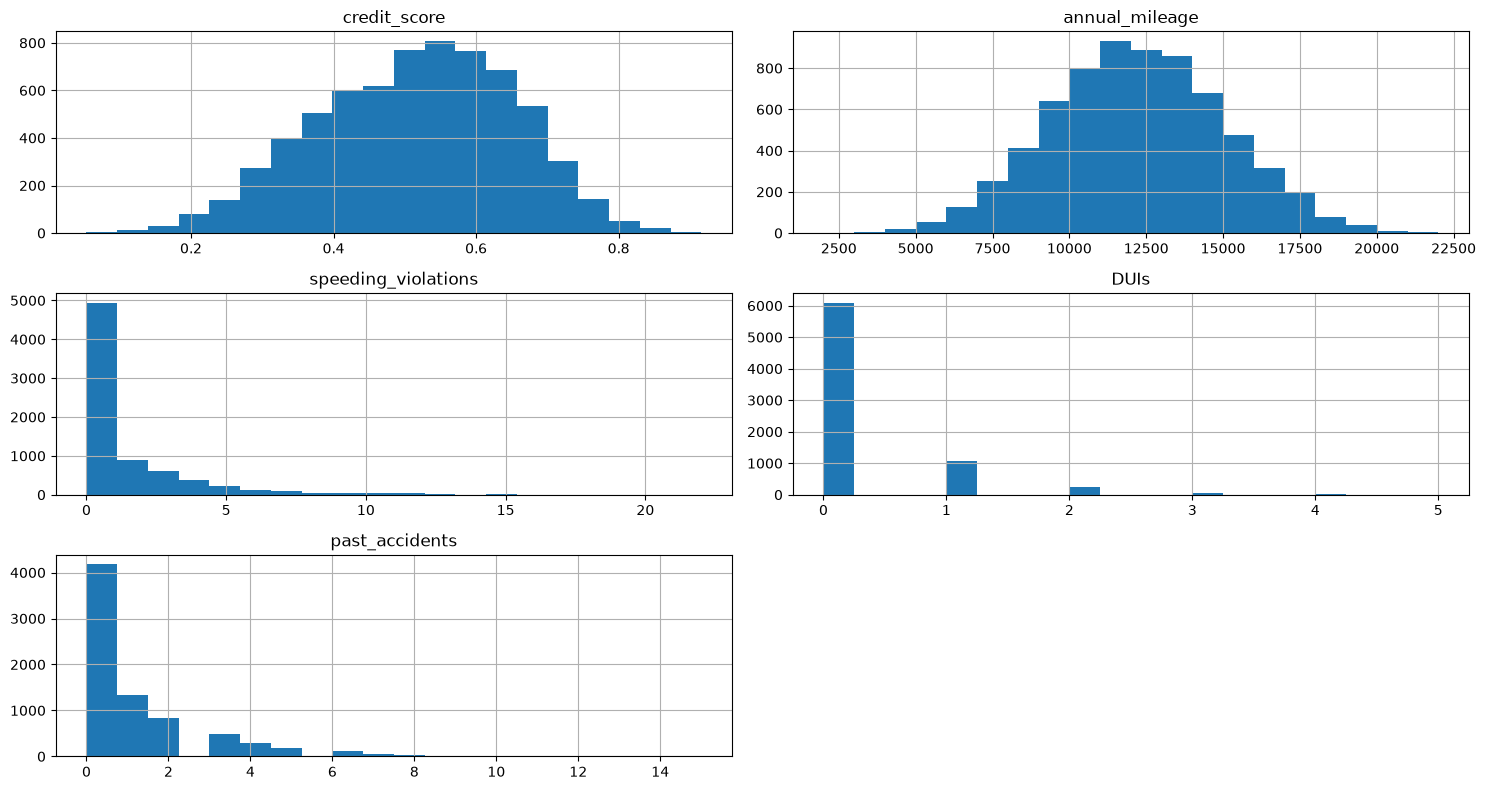

In [12]:
num_cols = ['credit_score', 'annual_mileage', 'speeding_violations', 'DUIs', 'past_accidents']
train[num_cols].hist(bins=20, figsize=(15, 8))
plt.tight_layout()
plt.show()

Распределения `credit_score` и `annual_mileage` похожи на колокол и почти симметричны: это согласуется с тем, что их средние и медианы близки (0.515 и 0.524, 11 713 и 12 000).

Счётчики `speeding_violations`, `DUIs` и `past_accidents` сильно скошены вправо: у всех трёх медиана равна 0, то есть по каждому из них хотя бы у половины клиентов значение равно нулю, и лишь у немногих оно большое. Эти длинные хвосты разберём на шаге 4.

Вычислим матрицу корреляций для числовых признаков и изобразим её: чем насыщеннее цвет, тем больше коэффициент корреляции по модулю (красный — положительная связь, синий — отрицательная):

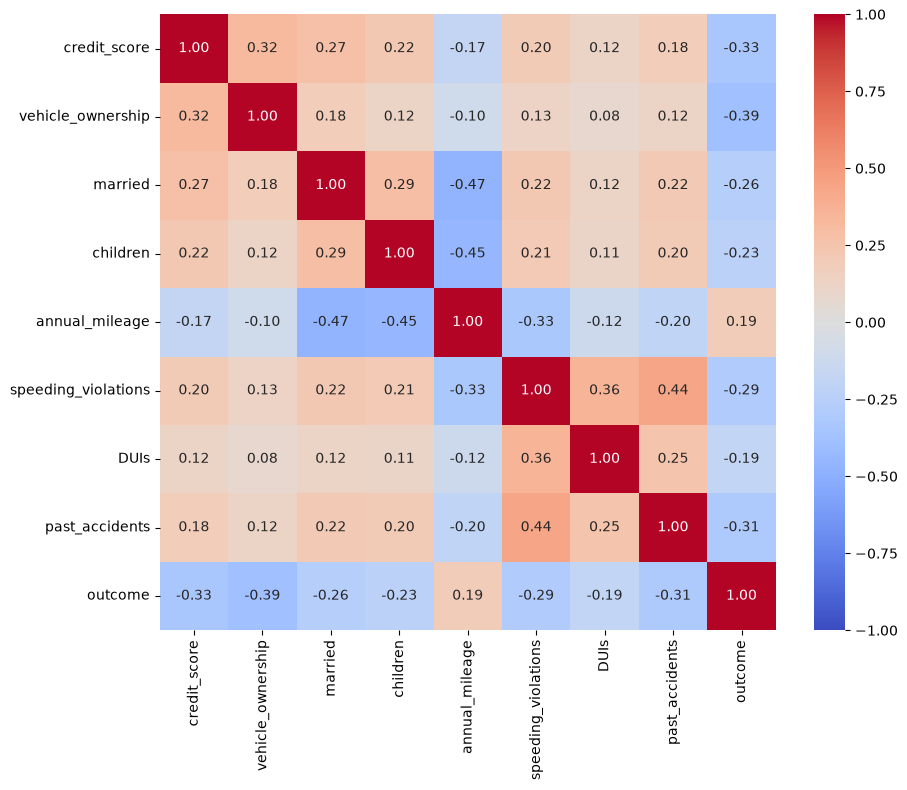

In [13]:
corr_mat = train.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(corr_mat, square=True, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm')
plt.show()

Выведем пары признаков, у которых коэффициент корреляции по модулю больше 0.3:

In [14]:
pairs = corr_mat.where(np.triu(np.abs(corr_mat) > 0.3, k=1)).stack().dropna().sort_values()
pairs.rename_axis(['признак 1', 'признак 2']).reset_index(name='корреляция')

,признак 1,признак 2,корреляция
0,married,annual_mileage,-0.473210
1,children,annual_mileage,-0.445859
2,vehicle_ownership,outcome,-0.385336
3,credit_score,outcome,-0.333197
4,annual_mileage,speeding_violations,-0.326946
5,past_accidents,outcome,-0.311646
6,credit_score,vehicle_ownership,0.316626
7,speeding_violations,DUIs,0.355650
8,speeding_violations,past_accidents,0.443110


Среди числовых признаков сильнее всего с `outcome` связаны `vehicle_ownership` (−0.39) и `credit_score` (−0.33). Корреляция отрицательная: клиенты со своей машиной и высоким кредитным рейтингом реже обращаются в страховую. Возможно, это более обеспеченные и аккуратные водители. Возраст и стаж в матрицу не попали, потому что это категориальные признаки; их рассмотрим отдельно ниже.

`speeding_violations` и `past_accidents` связаны между собой (0.44): у кого больше штрафов, у того, как правило, больше и аварий.

Семейные клиенты (`married`, `children`) проезжают за год меньше (−0.47 и −0.45).

Неожиданный результат дают `past_accidents` (−0.31) и `speeding_violations` (−0.29): они связаны с `outcome` *отрицательно*, то есть клиенты с бОльшим числом аварий и штрафов реже обращаются в страховую. Можно предположить, что дело в стаже: аварии и штрафы накапливаются с годами. Проверим это предположение после графиков по категориальным признакам.

Посмотрим, как доля обращений в страховую зависит от значений категориальных признаков. Высота столбика — доля клиентов с этим значением признака, которые обращались в страховую. Например, столбик 16-25 на графике `age` — это доля обратившихся среди клиентов 16–25 лет (точные значения выведем ниже):

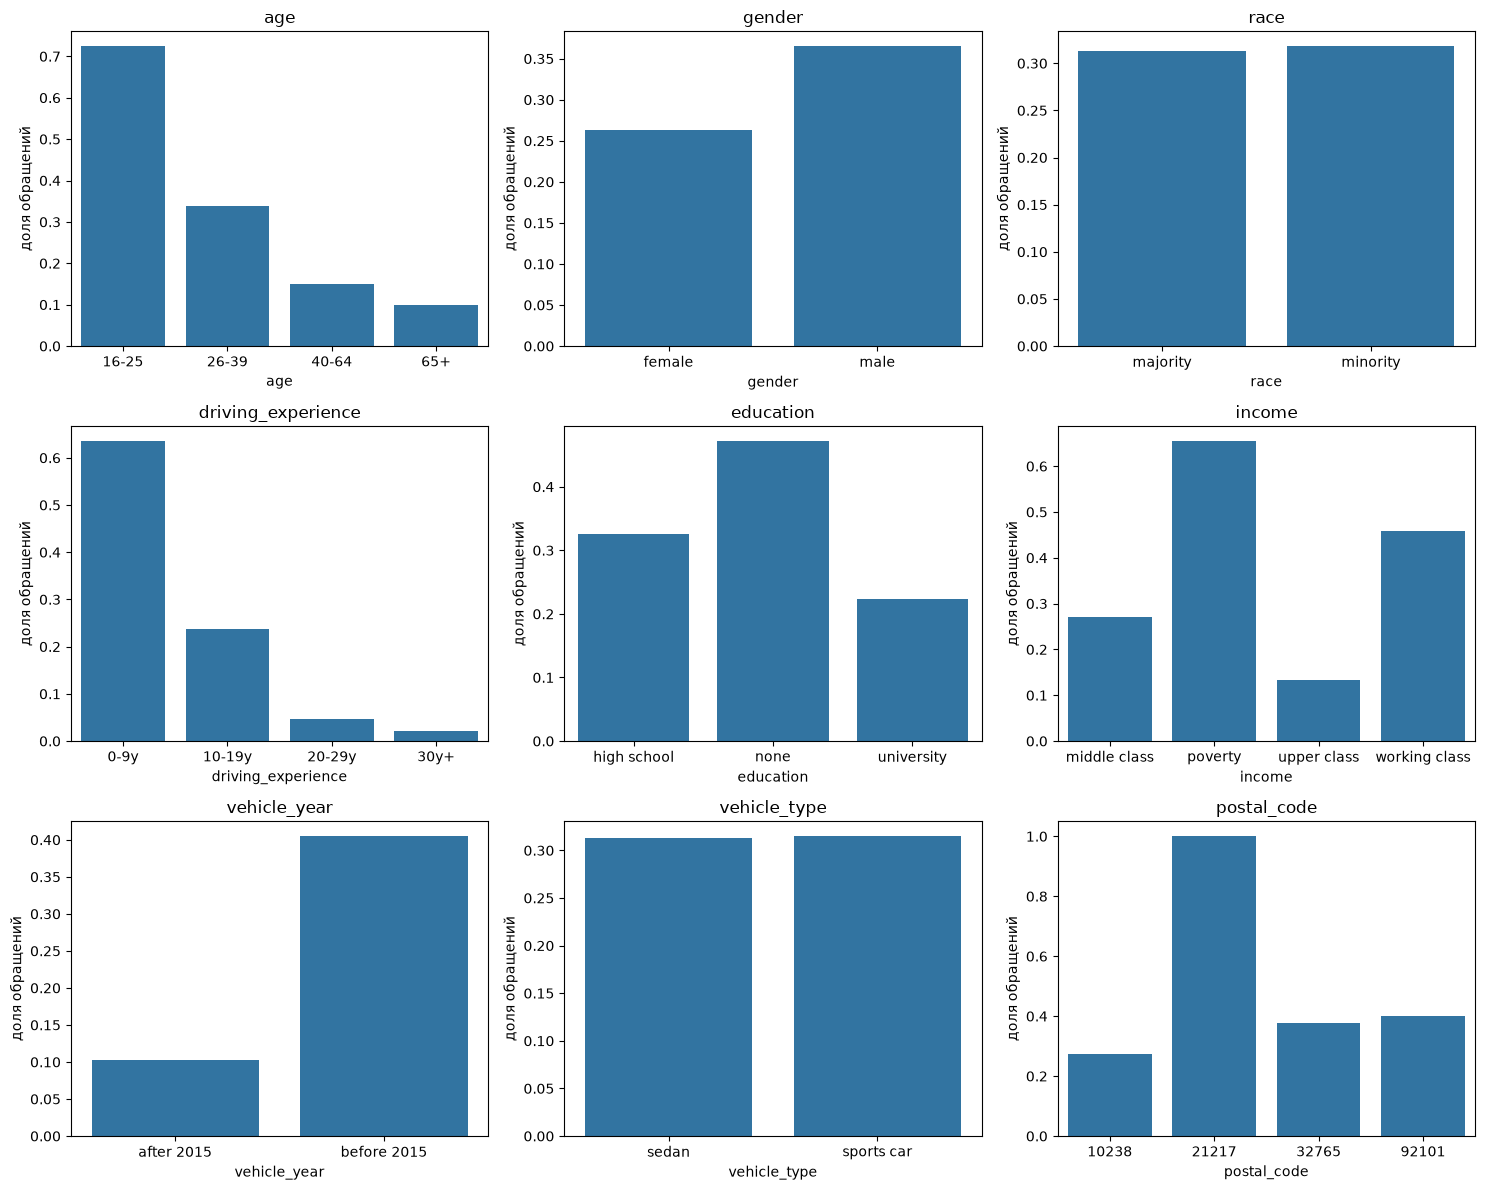

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, col in zip(axes.flat, cat_cols):
    sns.barplot(x=col, y='outcome', data=train, ax=ax, errorbar=None)
    ax.set_title(col)
    ax.set_ylabel('доля обращений')
plt.tight_layout()
plt.show()

Выведем точные значения: долю обращений (`mean`) и число клиентов (`size`) в каждой группе:

In [16]:
for col in cat_cols:
    print(train.groupby(col, observed=True)['outcome'].agg(['mean', 'size']).round(2), '\n')

       mean  size
age              
16-25  0.72  1494
26-39  0.34  2347
40-64  0.15  2172
65+    0.10  1487 

        mean  size
gender            
female  0.26  3799
male    0.37  3701 

          mean  size
race                
majority  0.31  6761
minority  0.32   739 

                    mean  size
driving_experience            
0-9y                0.63  2616
10-19y              0.24  2513
20-29y              0.05  1585
30y+                0.02   786 

             mean  size
education              
high school  0.33  3099
none         0.47  1438
university   0.22  2963 

               mean  size
income                   
middle class   0.27  1603
poverty        0.65  1365
upper class    0.13  3237
working class  0.46  1295 

              mean  size
vehicle_year            
after 2015     0.1  2274
before 2015    0.4  5226 

              mean  size
vehicle_type            
sedan         0.31  7141
sports car    0.31   359 

             mean  size
postal_code            
10238 

Доля обращений сильнее всего зависит от возраста и стажа. Среди молодых водителей (16–25 лет) в страховую обращались 72%, среди пожилых (65+) — только 10%. Со стажем то же самое: новички (0–9 лет) — 63%, водители со стажем 30+ лет — 2%. Неопытные водители, по-видимому, чаще попадают в аварии.

Доход тоже важен: среди бедных клиентов (`poverty`) обращались 65%, среди богатых (`upper class`) — 13%. Владельцы машин, выпущенных до 2015 года, обращаются примерно в 4 раза чаще владельцев новых машин (40% против 10%). Возможно, эти два эффекта связаны: у обеспеченных клиентов машины новее. Это проверим ниже.

Похожая картина с образованием: без образования — 47%, с высшим — 22%. Мужчины обращаются чаще женщин (37% против 26%).

А вот `race` и `vehicle_type` на `outcome` почти не влияют: доли в группах практически одинаковые. Значит, эти признаки вряд ли помогут модели.

Обратим внимание на почтовый индекс 21217: все 84 клиента с этим индексом обращались в страховую (доля 1.00). Это особенность данных, объяснить её по имеющимся признакам нельзя.

Проверим связь дохода с годом выпуска машины. Для каждого уровня дохода посчитаем доли машин, выпущенных до и после 2015 года:

In [17]:
pd.crosstab(train['income'], train['vehicle_year'], normalize='index').round(2)

vehicle_year,after 2015,before 2015
income,,
middle class,0.27,0.73
poverty,0.07,0.93
upper class,0.48,0.52
working class,0.15,0.85


Чем выше доход, тем чаще у клиента новая машина (выпущена после 2015 года): у бедных (`poverty`) — 7%, у рабочего класса (`working class`) — 15%, у среднего класса (`middle class`) — 27%, у богатых (`upper class`) — 48%. Так что связь действительно есть. Если бы разницу в обращениях между бедными и богатыми объяснял только год выпуска машины, то при одинаковом годе выпуска она бы исчезла. Сравним доли обращений по уровню дохода отдельно для старых и для новых машин:

In [18]:
train.groupby(['vehicle_year', 'income'], observed=True)['outcome'].mean().unstack().round(2)

income,middle class,poverty,upper class,working class
vehicle_year,,,,
after 2015,0.12,0.39,0.07,0.22
before 2015,0.32,0.67,0.19,0.50


Независимо от года выпуска машины бедные клиенты обращаются в страховую намного чаще богатых: среди владельцев машин, выпущенных до 2015 года, — 67% против 19%, выпущенных после 2015 года, — 39% против 7%. Значит, разница между бедными и богатыми объясняется не только тем, что у богатых машины новее.

Теперь проверим предположение о стаже. Посмотрим на среднее число аварий, штрафов, случаев вождения в нетрезвом виде и на долю обращений в каждой группе стажа:

In [19]:
train.groupby('driving_experience', observed=True)[['past_accidents', 'speeding_violations', 'DUIs', 'outcome']].mean().round(2)

,past_accidents,speeding_violations,DUIs,outcome
driving_experience,,,,
0-9y,0.00,0.00,0.00,0.63
10-19y,0.97,1.28,0.22,0.24
20-29y,1.94,2.72,0.47,0.05
30y+,3.04,4.40,0.65,0.02


Аварии и штрафы действительно накапливаются со стажем: в среднем 0.97 аварии при стаже 10–19 лет, 1.94 при стаже 20–29 лет и 3.04 при стаже 30+ лет (у новичков — 0, об этом ниже). Доля обращений при этом падает: 63% → 24% → 5% → 2%.

У новичков все средние равны нулю. Проверим, что у них действительно нет ни одной аварии, штрафа и случая вождения в нетрезвом виде (выведем максимальные значения):

In [20]:
train.loc[train['driving_experience'] == '0-9y', ['past_accidents', 'speeding_violations', 'DUIs']].max()

past_accidents         0
speeding_violations    0
DUIs                   0
dtype: int64

У всех 2616 водителей со стажем 0–9 лет нет ни одной аварии, штрафа или случая вождения в нетрезвом виде: максимальные значения этих признаков равны 0. Можно предположить, что для новичков история вождения в датасете не ведётся и эти признаки у них просто заполнены нулями. При этом доля обращений у новичков самая высокая (63%).

Если отрицательная связь аварий и штрафов с `outcome` объясняется стажем, то при одинаковом стаже она должна почти исчезнуть. Посчитаем долю обращений отдельно для каждой группы стажа и каждого числа аварий, а затем штрафов (3 и больше объединим в одну группу). У новичков аварий и штрафов нет, поэтому в их столбце заполнена только первая строка:

In [21]:
for col in ['past_accidents', 'speeding_violations']:
    counts = train[col].clip(upper=3)  # 3 и больше — одна группа
    print(train.groupby(['driving_experience', counts], observed=True)['outcome'].mean().unstack(0).round(2), '\n')

driving_experience  0-9y  10-19y  20-29y  30y+
past_accidents                                
0                   0.63    0.26    0.05  0.05
1                    NaN    0.22    0.05  0.03
2                    NaN    0.22    0.07  0.01
3                    NaN    0.23    0.03  0.01 

driving_experience   0-9y  10-19y  20-29y  30y+
speeding_violations                            
0                    0.63    0.20    0.06  0.07
1                     NaN    0.22    0.03  0.01
2                     NaN    0.28    0.06  0.02
3                     NaN    0.30    0.04  0.02 



При одинаковом стаже доля обращений от числа прошлых аварий зависит слабо: внутри каждой группы стажа она меняется всего на несколько процентных пунктов (например, при стаже 10–19 лет обращаются 26% клиентов без аварий и 22–23% клиентов с одной, двумя, тремя и более авариями), тогда как между группами стажа — с 63% до 2%. Для штрафов при стаже 10–19 лет связь даже становится положительной: доля обращений растёт с 20% у клиентов без штрафов до 30% у клиентов с тремя и более штрафами. Значит, отрицательная корреляция аварий и штрафов с `outcome` по всей выборке возникает из-за стажа: опытные водители накопили много аварий и штрафов, но обращаются редко. Это пример того, что корреляция не означает причинно-следственной связи.

## 4. Выбросы

Построим ящики с усами для количественных признаков. Значения за пределами усов (дальше чем 1.5 межквартильного расстояния от краёв ящика — *эвристика Тьюки*) обычно считают выбросами:

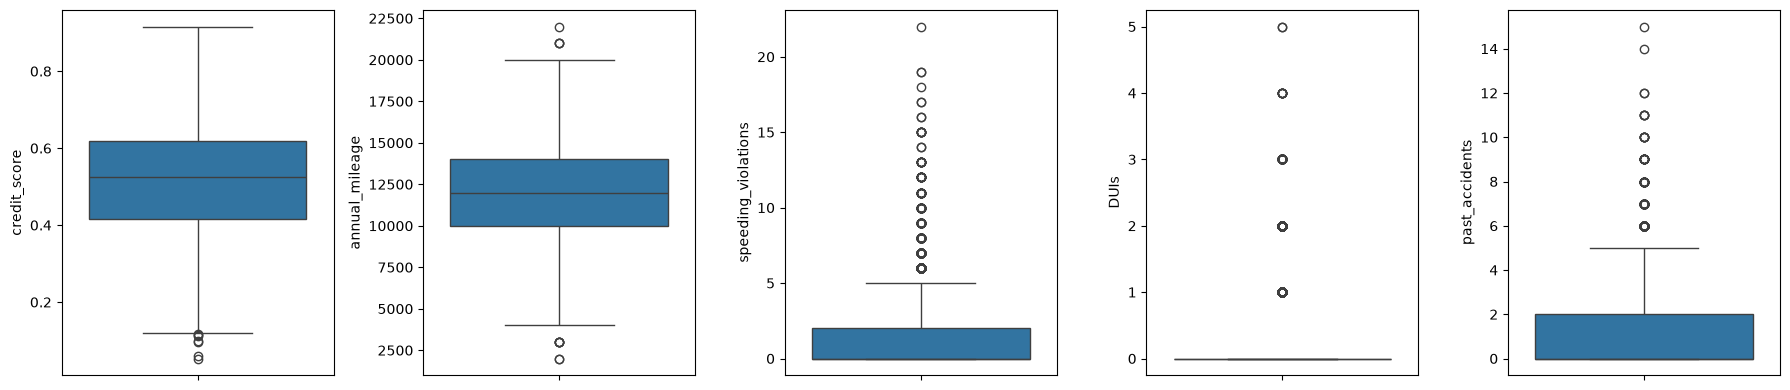

In [22]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=col, data=train, ax=ax)
plt.tight_layout()
plt.show()

Найдём квантили этих признаков:

In [23]:
train[num_cols].quantile([0.5, 0.75, 0.9, 0.95, 0.99, 1])

,credit_score,annual_mileage,speeding_violations,DUIs,past_accidents
0.50,0.524169,12000.0,0.0,0.0,0.0
0.75,0.617338,14000.0,2.0,0.0,2.0
0.90,0.686989,15000.0,4.0,1.0,3.0
0.95,0.722600,16000.0,6.0,1.0,5.0
0.99,0.794278,18000.0,10.0,2.0,7.0
1.00,0.915883,22000.0,22.0,5.0,15.0


Посчитаем, сколько объектов выходит за усы у каждого признака:

In [24]:
Q1 = train[num_cols].quantile(0.25)
Q3 = train[num_cols].quantile(0.75)
IQR = Q3 - Q1
((train[num_cols] < Q1 - 1.5*IQR) | (train[num_cols] > Q3 + 1.5*IQR)).sum()

credit_score              7
annual_mileage           11
speeding_violations     421
DUIs                   1403
past_accidents          208
dtype: int64

Посмотрим, какой стаж у клиентов с очень большими значениями — больше 10 штрафов или больше 7 аварий (это значения выше 99%-квантилей):

In [25]:
extreme = train[(train['speeding_violations'] > 10) | (train['past_accidents'] > 7)]
print('Клиентов с такими значениями:', len(extreme))
extreme['driving_experience'].value_counts()

Клиентов с такими значениями: 117


driving_experience
30y+      91
20-29y    26
0-9y       0
10-19y     0
Name: count, dtype: int64

У `credit_score` и `annual_mileage` за усами всего 7 и 11 точек, и значения вполне реальные (пробег 2 000 или 22 000 в год — нормально).

У `speeding_violations` и `past_accidents` за усами 421 и 208 клиентов (5.6% и 2.8%), максимумы — 22 штрафа и 15 аварий. Но квантили уровня 0.99 равны 10 штрафам и 7 авариям, а больше 10 штрафов или больше 7 аварий всего у 117 клиентов (1.6%), и все они — водители со стажем от 20 лет (91 из них — со стажем 30+). Это согласуется с тем, что штрафы и аварии накапливаются со стажем (шаг 3). Так что это редкие, но вполне возможные значения.

У `DUIs` ящик сжался в линию на нуле: квантиль уровня 0.75 равен 0, то есть по меньшей мере у 75% клиентов не было ни одного случая вождения в нетрезвом виде. Из-за этого эвристика Тьюки объявляет выбросом любого, у кого был хотя бы один случай, — таких 1403 клиента (18.7%). Здесь это правило явно не подходит.

Большие значения встречаются у опытных водителей и описывают хвосты распределения, а просто выкидывать такие выбросы неправильно. Поэтому выбросы не удаляем.

## 5. Пропущенные значения

Посмотрим, сколько пропущенных значений в каждом столбце обучающей выборки:

In [26]:
X_train.isna().sum()

age                      0
gender                   0
race                     0
driving_experience       0
education                0
income                   0
credit_score           748
vehicle_ownership        0
vehicle_year             0
married                  0
children                 0
postal_code              0
annual_mileage         709
vehicle_type             0
speeding_violations      0
DUIs                     0
past_accidents           0
dtype: int64

Посчитаем также долю строк, в которых есть хотя бы один пропуск:

In [27]:
X_train.isna().any(axis=1).mean()

np.float64(0.1848)

Пропуски есть только в `credit_score` (748) и `annual_mileage` (709), но строк хотя бы с одним пропуском — 18.5% обучающей выборки. Удалять такие строки неразумно: потеряем почти пятую часть данных. Поэтому заполним пропуски медианами, посчитанными по обучающей выборке. Медиана, в отличие от среднего, мало чувствительна к выбросам:

In [28]:
from sklearn.impute import SimpleImputer

miss_cols = ['credit_score', 'annual_mileage']
imp_num = SimpleImputer(strategy='median')
imp_num.fit(X_train[miss_cols])
X_train[miss_cols] = imp_num.transform(X_train[miss_cols])
X_test[miss_cols] = imp_num.transform(X_test[miss_cols])
imp_num.statistics_

array([5.2416915e-01, 1.2000000e+04])

Медианы равны 0.524 для `credit_score` и 12 000 для `annual_mileage`. Проверим, что пропусков не осталось ни в обучающей, ни в тестовой выборке:

In [29]:
X_train.isna().sum().sum(), X_test.isna().sum().sum()

(np.int64(0), np.int64(0))

Пропусков не осталось.

## 6. Обработка категориальных признаков

Алгоритмы scikit-learn почти не умеют работать с категориальными признаками напрямую, поэтому закодируем их методом *бинаризации* (*one-hot encoding*): признак, принимающий $s$ значений, заменяется на $s$ признаков со значениями 0 или 1. Например, вместо `income` появятся столбцы `income_poverty`, `income_working class` и т.д., и у каждого клиента единица будет стоять ровно в одном из них. Для бинарных признаков (`gender`, `race`, `vehicle_year`, `vehicle_type`) достаточно одного столбца, поэтому второй не создаём (`drop='if_binary'`).

Бинаризацию настраиваем только по обучающей выборке:

In [30]:
from sklearn.preprocessing import OneHotEncoder

enc = OneHotEncoder(drop='if_binary', sparse_output=False)
enc.fit(X_train[cat_cols])

def encode(X):
    dummies = pd.DataFrame(enc.transform(X[cat_cols]), columns=enc.get_feature_names_out(), index=X.index)
    return pd.concat((X, dummies), axis=1).drop(cat_cols, axis=1)

X_train = encode(X_train)
X_test = encode(X_test)
X_train.shape, X_test.shape

((7500, 31), (2500, 31))

Число признаков выросло с 17 до 31, и теперь все они числовые.

## 7. Нормализация

Признаки имеют очень разные масштабы: пробег измеряется тысячами, а кредитный рейтинг лежит от 0 до 1. Метод ближайших соседей считает расстояния между объектами, и без нормализации признаки с большими значениями (пробег) перевешивали бы все остальные.

Наиболее часто используют один из трёх способов:
- *приведение к отрезку [0, 1]* — линейное преобразование, приводящее все значения к заданному отрезку;
- *стандартизация* — линейное преобразование, приводящее все значения к нулевому среднему и единичному стандартному отклонению;
- *нормализация* — приведение данных к единичной норме.

Проведём стандартизацию всех признаков: из каждого признака вычтем среднее и поделим на стандартное отклонение (оба считаются по обучающей выборке):

In [31]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)
X_train = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)
X_train.describe().loc[['mean', 'std']].round(2)

,credit_score,vehicle_ownership,married,children,annual_mileage,speeding_violations,DUIs,past_accidents,age_16-25,age_26-39,...,income_middle class,income_poverty,income_upper class,income_working class,vehicle_year_before 2015,vehicle_type_sports car,postal_code_10238,postal_code_21217,postal_code_32765,postal_code_92101
mean,0.0,-0.0,-0.0,0.0,0.0,0.0,-0.0,-0.0,0.0,0.0,...,-0.0,0.0,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


После стандартизации у всех признаков обучающей выборки среднее 0 и стандартное отклонение 1, так что все они вносят в расстояние сопоставимый вклад.

## 8. Классификатор ближайших соседей

Используем метод $k$ ближайших соседей ($k\text{NN}$): клиент относится к тому классу, к которому принадлежит большинство из $k$ самых похожих на него клиентов обучающей выборки. Почему этот метод:
- он не делает предположений о форме границы между классами;
- он учитывает все признаки одновременно, а с обращениями в страховую, как видно из шага 3, связаны сразу многие из них (возраст, стаж, доход, год выпуска машины, кредитный рейтинг);
- его логика естественна для страхования: если большинство похожих клиентов обращались в страховую, то, скорее всего, обратится и этот клиент;
- при 7500 объектах и 31 признаке он работает быстро;
- у него один основной гиперпараметр — число соседей $k$, и его удобно подобрать кросс-валидацией.

Недостаток метода — чувствительность к масштабу признаков, поэтому на шаге 7 мы привели их к одному масштабу.

Начнём с $k = 5$ (значение по умолчанию):

In [32]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

y_train_predict = model.predict(X_train)
y_test_predict = model.predict(X_test)

accuracy_score(y_train, y_train_predict), accuracy_score(y_test, y_test_predict)

(0.8708, 0.8108)

При $k = 5$ модель правильно классифицирует 87% клиентов обучающей выборки и 81% тестовой. Качество модели оцениваем по тестовой выборке.

81% — заметно лучше, чем 69% у тривиальной модели, которая всем отвечает «не обратится» (доля класса 0 равна 1 − 0.313 ≈ 0.69). Значит, признаки действительно помогают предсказывать `outcome`.

## 9. Ошибки и выбор числа соседей

Вычислим ошибки на обучающей и тестовой выборках и напечатаем матрицу рассогласования для тестовой выборки (строки — предсказанный класс, столбцы — истинный). Ошибки разных моделей будем собирать в одну таблицу `err_table`:

In [33]:
from sklearn.metrics import confusion_matrix

err_train = np.mean(y_train != y_train_predict)
err_test  = np.mean(y_test  != y_test_predict)

err_table = pd.DataFrame(columns=('train', 'test'))
err_table.loc['kNN, k = 5', :] = (err_train, err_test)

print('Ошибка на train:', err_train)
print('Ошибка на test: ', err_test)
print(confusion_matrix(y_test_predict, y_test))

Ошибка на train: 0.1292
Ошибка на test:  0.1892
[[1486  242]
 [ 231  541]]


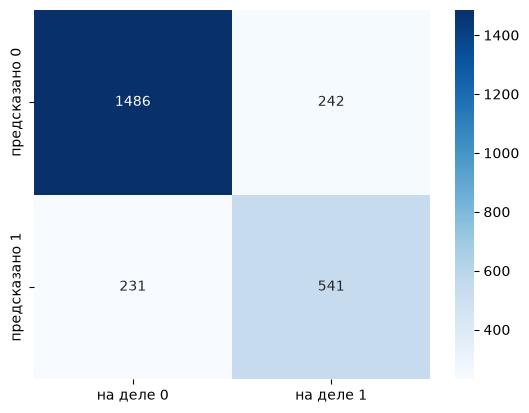

In [34]:
sns.heatmap(confusion_matrix(y_test_predict, y_test), annot=True, fmt='d', cmap='Blues',
            xticklabels=['на деле 0', 'на деле 1'], yticklabels=['предсказано 0', 'предсказано 1'])
plt.show()

Ошибка на обучающей выборке около 13%, на тестовой около 19%.

Матрица рассогласования показывает, на каких клиентах модель ошибается. Из 1717 клиентов, которые не обращались (первый столбец), модель правильно распознала 1486 (87%), а для 231 клиента выдала ложную тревогу. А из 783 клиентов, которые обратились (второй столбец), она нашла только 69%, остальных пропустила — это промахи.

Модель заметно хуже находит клиентов, которые обратились в страховую. Вероятно, это следствие несбалансированности классов: клиентов, которые не обращались, более чем вдвое больше, чем обратившихся, поэтому среди соседей они встречаются чаще и перевешивают при голосовании. Для страховой такие промахи опаснее ложных тревог: клиенту, который обратится, продадут слишком дешёвую страховку.

Подберём оптимальное число соседей $k$ с помощью 5-кратной кросс-валидации на обучающей выборке (тестовая выборка в подборе не участвует):

In [35]:
from sklearn.model_selection import GridSearchCV

k_arr = np.array([1, 3, 5, 7, 10, 15, 20, 25, 30, 40, 50])
grid = GridSearchCV(KNeighborsClassifier(), {'n_neighbors': k_arr}, scoring='accuracy', return_train_score=True)
grid.fit(X_train, y_train)
grid.best_params_, grid.best_score_

({'n_neighbors': np.int64(25)}, np.float64(0.8281333333333334))

Выведем средние ошибки на обучающих частях и на кросс-валидации, а также стандартное отклонение ошибки на кросс-валидации (насколько различаются ошибки в пяти прогонах):

In [36]:
err_cv_train = 1 - grid.cv_results_['mean_train_score']
err_cv = 1 - grid.cv_results_['mean_test_score']
std_cv = grid.cv_results_['std_test_score']

pd.DataFrame({'k': k_arr, 'ошибка train': err_cv_train, 'ошибка кросс-валидации': err_cv,
              'стандартное отклонение': std_cv}).round(4)

,k,ошибка train,ошибка кросс-валидации,стандартное отклонение
0,1,0.0004,0.2068,0.0086
1,3,0.1056,0.1840,0.0084
2,5,0.1300,0.1823,0.0115
3,7,0.1382,0.1768,0.0074
4,10,0.1495,0.1744,0.0069
5,15,0.1505,0.1757,0.0089
6,20,0.1582,0.1732,0.0102
7,25,0.1588,0.1719,0.0101
8,30,0.1627,0.1753,0.0118
9,40,0.1661,0.1751,0.0088


Изобразим эти ошибки на графике. Ось $k$ развёрнута, чтобы слева направо модель становилась сложнее: чем меньше $k$, тем сильнее модель подстраивается под отдельных клиентов. Закрашенная полоса — ошибка на кросс-валидации плюс-минус стандартное отклонение:

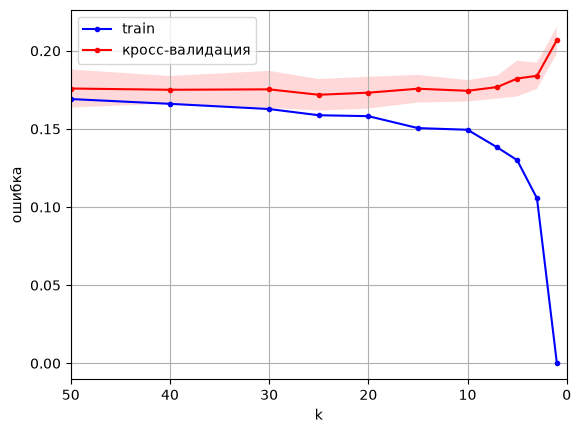

In [37]:
plt.plot(k_arr, err_cv_train, 'b.-', label='train')
plt.plot(k_arr, err_cv, 'r.-', label='кросс-валидация')
plt.fill_between(k_arr, err_cv - std_cv, err_cv + std_cv, alpha=0.15, facecolor='red')
plt.xlim([max(k_arr), 0])
plt.xlabel('k')
plt.ylabel('ошибка')
plt.legend()
plt.grid()
plt.show()

При $k = 1$ ошибка на обучающей выборке почти нулевая (0.04%), а на кросс-валидации максимальная (20.7%). Это переобучение: модель просто запоминает обучающие объекты, ведь ближайший сосед каждого клиента — он сам.

С ростом $k$ ошибка на обучающей выборке растёт. Ошибка на кросс-валидации сначала быстро падает (с 20.7% при $k = 1$ до 17.7% при $k = 7$), а дальше почти не меняется: модель перестаёт подстраиваться под отдельных клиентов и улавливает общие закономерности. Минимум ошибки на кросс-валидации (17.2%) достигается при $k = 25$, но при $k$ от 7 до 50 ошибка лежит между 17.2% и 17.7%, а стандартное отклонение ошибки на кросс-валидации — около 1% (закрашенная полоса). Так что $k = 25$ лежит на широком плато, и любое $k$ из этого диапазона дало бы почти тот же результат.

Выберем $k = 25$ (минимум ошибки на кросс-валидации) и обучим модель с этим значением:

In [38]:
best_k = grid.best_params_['n_neighbors']
model = KNeighborsClassifier(n_neighbors=best_k)
model.fit(X_train, y_train)

y_train_predict = model.predict(X_train)
y_test_predict = model.predict(X_test)

err_train = np.mean(y_train != y_train_predict)
err_test  = np.mean(y_test  != y_test_predict)
err_table.loc[f'kNN, k = {best_k}', :] = (err_train, err_test)

print('k =', best_k)
print('Ошибка на train:', err_train)
print('Ошибка на test: ', err_test)
print(confusion_matrix(y_test_predict, y_test))

k = 25
Ошибка на train: 0.1588
Ошибка на test:  0.1788
[[1516  246]
 [ 201  537]]


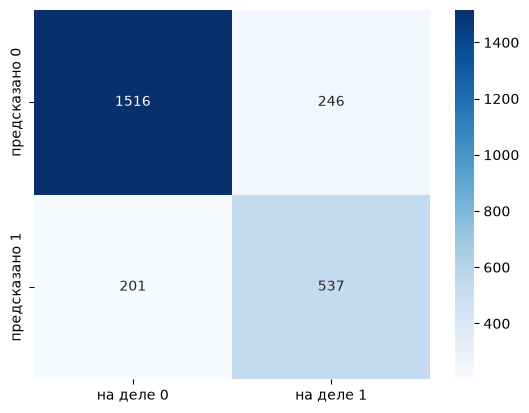

In [39]:
sns.heatmap(confusion_matrix(y_test_predict, y_test), annot=True, fmt='d', cmap='Blues',
            xticklabels=['на деле 0', 'на деле 1'], yticklabels=['предсказано 0', 'предсказано 1'])
plt.show()

С $k = 25$ ошибка на тестовой выборке уменьшилась примерно с 19% до 17.9% (доля правильных ответов — 82%). Ошибка на обучающей выборке (15.9%) теперь близка к ошибке на тестовой, значит, модель не переобучена.

По матрице рассогласования: ложных тревог стало меньше (231 → 201), а доля найденных клиентов, которые обратились, почти не изменилась: модель находит 537 из 783 (69%). Так что главная слабость модели осталась: она пропускает примерно треть клиентов, которые обратились в страховую.

## 10. Другие классификаторы

Для сравнения запустим ещё два метода: логистическую регрессию и случайный лес. Ошибки добавляем в ту же таблицу.

In [40]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

err_train = np.mean(y_train != lr_model.predict(X_train))
err_test  = np.mean(y_test  != lr_model.predict(X_test))
err_table.loc['Логистическая регрессия', :] = (err_train, err_test)
print(confusion_matrix(lr_model.predict(X_test), y_test))

[[1532  194]
 [ 185  589]]


In [41]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=300, random_state=42)
rf_model.fit(X_train, y_train)

err_train = np.mean(y_train != rf_model.predict(X_train))
err_test  = np.mean(y_test  != rf_model.predict(X_test))
err_table.loc['Случайный лес', :] = (err_train, err_test)
print(confusion_matrix(rf_model.predict(X_test), y_test))

[[1510  220]
 [ 207  563]]


In [42]:
err_table.astype(float).round(4)

,train,test
"kNN, k = 5",0.1292,0.1892
"kNN, k = 25",0.1588,0.1788
Логистическая регрессия,0.1423,0.1516
Случайный лес,0.0004,0.1708


Логистическая регрессия дала наименьшую ошибку на тестовой выборке — 15.2% против 17.9% у $k\text{NN}$ с $k = 25$. Она же находит больше клиентов, которые обратились: 589 из 783 (75%) против 537 у $k\text{NN}$. Ошибки логистической регрессии на обучающей и тестовой выборках близки (14.2% и 15.2%), то есть переобучения нет.

Случайный лес почти без ошибок запомнил обучающую выборку (0.04%), а на тестовой ошибается в 17.1% случаев: это немного лучше $k\text{NN}$, но хуже логистической регрессии.

Случайный лес позволяет оценить *важность* признаков: чем значение больше, тем признак важнее. Это ответ на вопрос заказчика о том, какие признаки важнее всего (см. описание задачи):

In [43]:
importances = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
importances.head(10)

credit_score                0.156381
driving_experience_0-9y     0.102238
annual_mileage              0.094526
vehicle_ownership           0.079658
vehicle_year_before 2015    0.056318
speeding_violations         0.052955
age_16-25                   0.052182
past_accidents              0.047852
gender_male                 0.031698
married                     0.023974
dtype: float64

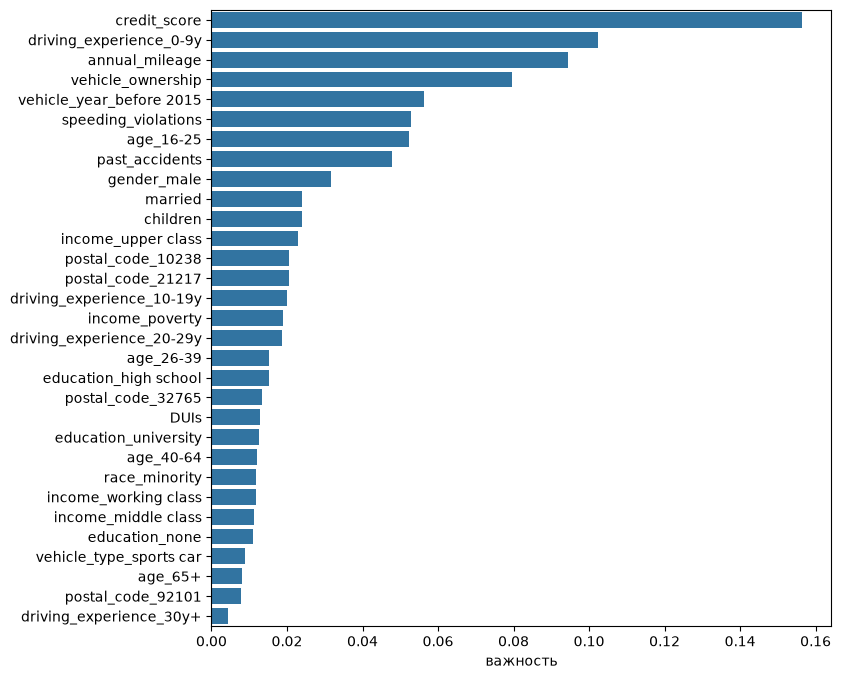

In [44]:
plt.figure(figsize=(8, 8))
sns.barplot(y=importances.index, x=importances, orient='h')
plt.xlabel('важность')
plt.ylabel('')
plt.show()

Самые важные признаки по оценке леса — `credit_score`, стаж до 10 лет (`driving_experience_0-9y`), `annual_mileage`, `vehicle_ownership` и год выпуска машины (`vehicle_year_before 2015`). Стаж, наличие своей машины, кредитный рейтинг и год выпуска машины уже выделялись на шаге 3 как сильнее всего связанные с обращениями. Признаки `race_minority` и `vehicle_type_sports car` оказались в нижней части списка, как мы и ожидали по графикам долей обращений.

Оценка важности леса и доли обращений на шаге 3 — разные меры, поэтому порядок признаков в них не обязан совпадать.

## 13. Общие выводы

**Что сделали.** Решали задачу бинарной классификации: по данным о 10 000 клиентах страховой компании предсказывали, подаст ли клиент страховое требование (`outcome`). Разбили данные на обучающую (7500) и тестовую (2500) выборки, исследовали данные, разобрались с выбросами, заполнили пропуски медианами, провели бинаризацию категориальных признаков и привели все признаки к одному масштабу. Все параметры обработки считали только по обучающей выборке.

**Что узнали о данных.** Сильнее всего доля обращений различается между группами стажа и возраста: из новичков (стаж 0–9 лет) обращались 63%, из водителей со стажем 30+ лет — 2%. Также важны доход, год выпуска машины, наличие своей машины и кредитный рейтинг. Признаки `race` и `vehicle_type` на обращения почти не влияют.

Неожиданным оказалось, что прошлые аварии и штрафы связаны с `outcome` отрицательно. Проверка показала, что это эффект стажа: аварии и штрафы накапливаются с годами, а опытные водители обращаются редко. При одинаковом стаже доля обращений от числа прошлых аварий зависит слабо. Это пример того, что корреляция не означает причинно-следственной связи.

**Модели.** Метод $k$ ближайших соседей с подобранным на кросс-валидации $k = 25$ ошибается на тестовой выборке в 17.9% случаев (доля правильных ответов 82%). Это заметно лучше тривиальной модели, которая всем отвечает «не обратится» и угадывает в 69% случаев. При $k = 1$ модель переобучается (ошибка на обучающей выборке почти нулевая, на кросс-валидации 20.7%), а при $k = 25$ ошибки на обучающей и тестовой выборках близки. Значение $k = 25$ выбрано по минимуму ошибки на кросс-валидации (17.2%); при $k$ от 7 до 50 эта ошибка почти одинакова (от 17.2% до 17.7%), так что точный выбор $k$ в этом диапазоне на результат почти не влияет. Из опробованных методов наименьшую ошибку на тестовой выборке дала логистическая регрессия — 15.2%. По оценке случайного леса, самые важные признаки — кредитный рейтинг, стаж до 10 лет, годовой пробег, наличие своей машины и год выпуска машины.

**Слабое место.** $k\text{NN}$ находит только 69% клиентов, которые действительно обратились в страховую. Вероятно, сказывается несбалансированность классов (31 на 69).

**Что можно улучшить.** Побороться с несбалансированностью классов и подобрать гиперпараметры логистической регрессии и случайного леса.